# Exercise 8: 1D Ground State via Simulated Annealing

### Premises:

- The expectation value of the Hamiltonian is $$ \langle \hat{\mathrm{H}} \rangle_\Psi = \frac{\int \mathrm{d}x \, \Psi^*(x)\hat{\mathrm{H}}\Psi(x)}{\int \mathrm{d}x \, |\Psi(x)|^2} = \int \mathrm{d}x \frac{|\Psi(x)|^2}{\int \mathrm{d}x' |\Psi(x')|^2} \frac{\hat{\mathrm{H}}\Psi(x)}{\Psi(x)} $$ where $p(x) = \frac{|\Psi(x)|^2}{\int \mathrm{d}x' |\Psi(x')|^2}$ can be sampled with the Metropolis algorithm ignoring the normalization factor, while the integrand $\frac{\hat{\mathrm{H}}\Psi(x)}{\Psi(x)}$ can be written analitically for the trial wavefunction.

- A wavefunction $\Psi(x)$ can be implemented computationally as a scalar function on a 1D lattice $\{x_i\}_{i=0}^{N-1}$ (given a spacing $\delta x$). Then, the (*linear and local*) Hamiltonian takes the form of a $N \times N$ matrix where differential operators are approximated by incremental ratios.

### Ex.8.1: Measure the energy of a trial state

> ***goal**: given a non-normalized* trial *wave function*
> $$ \Psi_{trial}^{\sigma, \mu}(x) \propto e^{-\frac{(x - \mu)^2}{2\sigma^2}} + e^{-\frac{(x + \mu)^2}{2\sigma^2}} $$
> *and a Hamiltonian that is not anaitically solvable (with $\hbar=1$ and $m=1$)*
> $$ \hat{\mathrm{H}} = \frac{1}{2}\big|-i\vec{\nabla}\big|^2 + x^4 - \frac{5}{2}x^2 $$
> *use the Metropolis algorithm (with a uniform* transition probability *) to sample the particle's probability distribution and compute (with data blocking) the expectation value $\langle \hat{\mathrm{H}} \rangle_\Psi$*

For starters, we can write analytically the action of the Hamiltonian on the wavefunction (ignoring the normalization of the wavefunction):
$$ \begin{align*}
\hat{\mathrm{H}}\Psi(x) &= \bigg[ -\frac{1}{2}\partial_x^2 + \hat{V}(x) \bigg] \bigg[ e^{-\frac{(x - \mu)^2}{2\sigma^2}} + e^{-\frac{(x + \mu)^2}{2\sigma^2}} \bigg] \\
&= -\frac{1}{2\sigma^4}\bigg\{ \big[ (x - \mu)^2 - \sigma^2 \big] e^{-\frac{(x - \mu)^2}{2\sigma^2}} + \big[ (x + \mu)^2 - \sigma^2 \big] e^{-\frac{(x + \mu)^2}{2\sigma^2}} \bigg\} + \hat{\mathrm{V}}(x)\Psi(x) \\
&= \bigg[ x^4 - \frac{5}{2}x^2 -  \frac{x^2 - \mu^2 + \sigma^2}{2\sigma^4} \bigg] \Psi(x) - \frac{\mu x}{\sigma^4} \bigg[ e^{-\frac{(x + \mu)^2}{2\sigma^2}} - e^{-\frac{(x - \mu)^2}{2\sigma^2}} \bigg] \\
\end{align*}$$

which gives an integrand equal to
$$
\frac{\hat{\mathrm{H}}\Psi(x)}{\Psi(x)} = x^4 - \frac{5}{2}x^2 -  \frac{x^2 - \mu^2 + \sigma^2}{2\sigma^4} + \frac{\mu x}{\sigma^4} \tanh{\frac{\mu x}{\sigma^2}} \qquad\text{where}\qquad \tanh{\frac{\mu x}{\sigma^2}} = - \frac{e^{-\frac{(x + \mu)^2}{2\sigma^2}} - e^{-\frac{(x - \mu)^2}{2\sigma^2}}}{e^{-\frac{(x + \mu)^2}{2\sigma^2}} + e^{-\frac{(x - \mu)^2}{2\sigma^2}}}
$$

to be integrated sampling a (non-normalized) probability distribution of
$$
p_{\mu, \sigma}(x) = \big| \Psi(x) \big|^2 = \big| e^{-\frac{(x - \mu)^2}{2\sigma^2}} + e^{-\frac{(x + \mu)^2}{2\sigma^2}} \big|^2
$$

Given these analytical functions, we just need to add a method for computing $\langle \hat{\mathrm{H}} \rangle$ in the `Random` class: this is a function that computes the $\langle \hat{\mathrm{H}} \rangle$ integral by sampling the probability distribution $p_{\mu, \sigma}$ and returns the series of block averages:
```cpp
std::vector<double> Random::ex8_energy_block_avgs(double mu, double sigma, int Nblk, int Nsmp, double delta) {
  auto integrand = [mu, sigma](double x) {
    double m2 = mu*mu, s2 = sigma*sigma, x2 = x*x;
    double s4 = s2*s2, x4 = x2*x2;
    return x4 - 2.5*x2 - (x2 - m2 + s2) / (2 * s4) + mu*x*std::tanh(mu*x / s2) / s4;
  };
  auto prob = [mu, sigma](double x) {
    double exp_minus = std::exp(- (x - mu) * (x - mu) / (2 * sigma * sigma));
    double exp_plus = std::exp(- (x + mu) * (x + mu) / (2 * sigma * sigma));
    return  (exp_plus + exp_minus) * (exp_plus + exp_minus);
  };

  /* sample the distributuion and compute block averages at the same time*/
  auto x_new = [this, delta](double& x_old) {
    return x_old + rannyu(-delta, delta);
  };
  double x = 0.0, x_old = x;
  double p = prob(x), p_old = p;

  //  int nacc = 0, natt = 0;
  std::vector<double> blk_avgs{};
  for (int block = 0; block < Nblk; block++) {
    double sum = 0.0;
    for (int smp = 0; smp < Nsmp; smp++) {
      /* generate new sample */
      do {
        x = x_new(x_old);
        p = prob(x);
        //  natt++;
      } while (rannyu() >= std::min(1.0, p / p_old));
      //  nacc++;
      x_old = x;
      p_old = p;

      /* add its contribution to the block average */
      sum += integrand(x);
    }
    blk_avgs.emplace_back(sum / Nsmp);
  }
  //  std::cerr << "Acceptance ratio: " << double(nacc) / natt << std::endl;

  return blk_avgs;
}
```

We can call it using `./run <Nblocks> ex8_energy_block_avgs <mu> <sigma> <Nsamples_per_block> <delta>`.

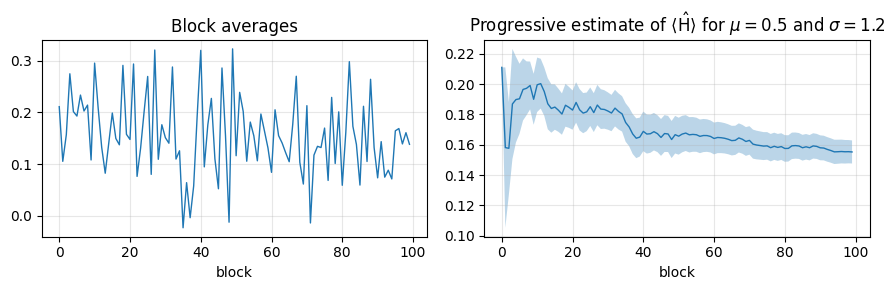

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import subprocess

def energy_block_averages(mu, sigma, Nblk, Nsmp):
    output = subprocess.run(["./run", str(Nblk), "ex8_energy_block_avgs", str(mu), str(sigma), str(Nsmp)], 
                            cwd="./rannyu_rng",
                            capture_output=True,
                            text=True,
                            check=True)
    return np.array(output.stdout.strip().split(), dtype=float)

def progressive_data(blk_estimates):
    progr_avg = np.zeros(Nblk)
    progr_avg2 = np.zeros(Nblk)
    progr_err = np.zeros(Nblk)
    for i, avg in enumerate(blk_estimates):
        for j in range(i, Nblk):
            progr_avg[j] += avg
            progr_avg2[j] += avg * avg
        progr_avg[i] /= i + 1
        progr_avg2[i] /= i + 1
        progr_err[i] = error(progr_avg[i], progr_avg2[i], i + 1)
    return progr_avg, progr_err

def error(avg, avg2, N):
    return np.sqrt((avg2 - avg*avg) / max(1, N - 1))
    
def plt_block_avgs(ax, blk_avgs, title):
    Nblk = blk_avgs.size
    ax.plot(range(Nblk), blk_avgs, lw=1)
    ax.set_xlabel("block")
    ax.set_title(title)
    ax.grid(alpha=0.3)

def plt_progr_avg(ax, avgs, errs, title):
    Nblk = avgs.size
    ax.plot(range(Nblk), avgs, lw=1)
    ax.fill_between(range(Nblk), avgs - errs, avgs + errs, alpha=0.3)
    ax.set_xlabel("block")
    ax.set_title(title)
    ax.grid(alpha=0.3)

mu = 0.5
sigma = 1.2
Nblk = 100
Nsmp = 5000

blk_avgs = energy_block_averages(mu, sigma, Nblk, Nsmp)
progr_avg, progr_err = progressive_data(blk_avgs)

fig, axs = plt.subplots(1, 2, figsize=(9,3))
plt_block_avgs(axs[0], blk_avgs, "Block averages")
plt_progr_avg(axs[1], progr_avg, progr_err, rf"Progressive estimate of $\langle \hat{{\mathrm{{H}}}} \rangle$ for $\mu = {mu}$ and $\sigma = {sigma}$")
fig.tight_layout()

### Ex.8.2: Simulated Annealing to minimize $\langle \hat{\mathrm{H}} \rangle_\Psi$ with respect to $\sigma$ and $\mu$

> ***goal**: use a SA algorithm to find the values of $(\sigma, \mu)$ that minimize $\langle \hat{\mathrm{H}} \rangle_\Psi$. Remember to*
> - *choose an appropriate initial temperature and temperature-update-law*
> - *compute $\langle \hat{\mathrm{H}} \rangle_\Psi$ with enough precision to appreciate the effect of adjusting the parameters*
>
> *Then show*
> - *$\langle \hat{\mathrm{H}} \rangle_\Psi$ as the SA algorithm progresses*
> - *the trajectory in parameter space of $(\mu, \sigma)$ as the SA algorithm progresses*
> 
> *Lastly, once the optimal $\tilde{\Psi}(x)$ have been obtained (with $(\tilde{\mu}, \tilde{\sigma})$)*
> - *show $\langle \hat{\mathrm{H}} \rangle_{\tilde{\Psi}}$ as a function of the number of blocks/MC steps*
> - *show a histogram obtained by sampling the resulting probability distribution $p(x) = \big| \tilde{\Psi}(x) \big|^2$, comparing it to its analytic curve and to the numerical solution of the Shrödinger equation ( see:* Premises *)*

To implement a Simulated Annealing process with a different `Random` class method we have:

```cpp
std::vector<std::pair<double, double>>
Random::ex8_parameters_trajectory(double mu, double sigma, int Nblk, int Nsmp) {
  std::vector<std::pair<double, double>> parameters_history{};
  parameters_history.emplace_back(mu, sigma);
  double T = 1.0;

  /* generate new parameters */
  double delta = 0.1;
  auto new_parameters = [this, delta](double &mu, double &sigma) {
    double theta = rannyu(0.0, 2 * pi), r = delta * std::sqrt(rannyu());
    mu = std::abs(mu + r * std::cos(theta));
    sigma = std::abs(sigma + r * std::sin(theta));
  };

  /* compute new energy */
  auto energy = [this, Nblk, Nsmp](double mu, double sigma) {
    std::vector blk_avgs = ex8_energy_block_avgs(mu, sigma, Nblk, Nsmp);
    double E_sum = 0.0;
    for (auto E : blk_avgs) {
      E_sum += E;
    }
    return E_sum / Nblk;
  };

  /* compare new and old parameters results */
  auto accept_adjustment = [this, &T](double E, double E_old) {
    double prob_ratio = std::exp(-(E - E_old) / T);
    return rannyu() < std::min(1.0, prob_ratio);
  };

  /* cool down */
  int steps_per_temperature = 100;
  double alpha = 0.95; /*  TODO: decide */
  double T_min = 1e-2;
  auto cool_down = [alpha](double &T) { T *= alpha; };

  /* SA LOOP */
  double E = energy(mu, sigma), E_old = E;
  double mu_old = mu, sigma_old = sigma;
  int current_step = 0;
  do {
    do {
      mu = mu_old, sigma = sigma_old;
      E = E_old;

      new_parameters(mu, sigma);
      E = energy(mu, sigma);
    } while (!accept_adjustment(E, E_old));
    parameters_history.emplace_back(mu, sigma);
    mu_old = mu, sigma_old = sigma;
    E_old = E;

    current_step++;

    if (current_step % steps_per_temperature == 0) {
      cool_down(T);
    }
  } while (T >= T_min);

  return parameters_history;
}
```


which, using lambda functions for simplicity, defines how to
- generate new parameters $(\mu', \sigma')$ close to the old ones within a distance (*in parameter space*) `delta`
- compute the new proposed parameters' expected energy (*using the previous `ex8_energy_block_avgs` functions*)
- decides wether to accept or reject this parameters adjustment using a Metropolis process that supposes a *Boltzmann-like* energy distribution in parameters space
- slightly lower the temperature every `steps_per_temperature` parameters adjustments

***note**: some parameters like `delta` (for the wavefunction sampling process in each energy evaluation) are computed dynamically from $(\mu, \sigma)$, others like `delta` for generating $(\mu', \sigma')$ and `alpha` for lowering the temperature are hardcoded.*

then plot the parameters trajectory during the process along with the energy surface in 3d, to cisually check that the parameters are actually moving towards lower points in the graph:

Expected energy minimum: E = -0.4444 at mu = 0.797, sigma = 0.616


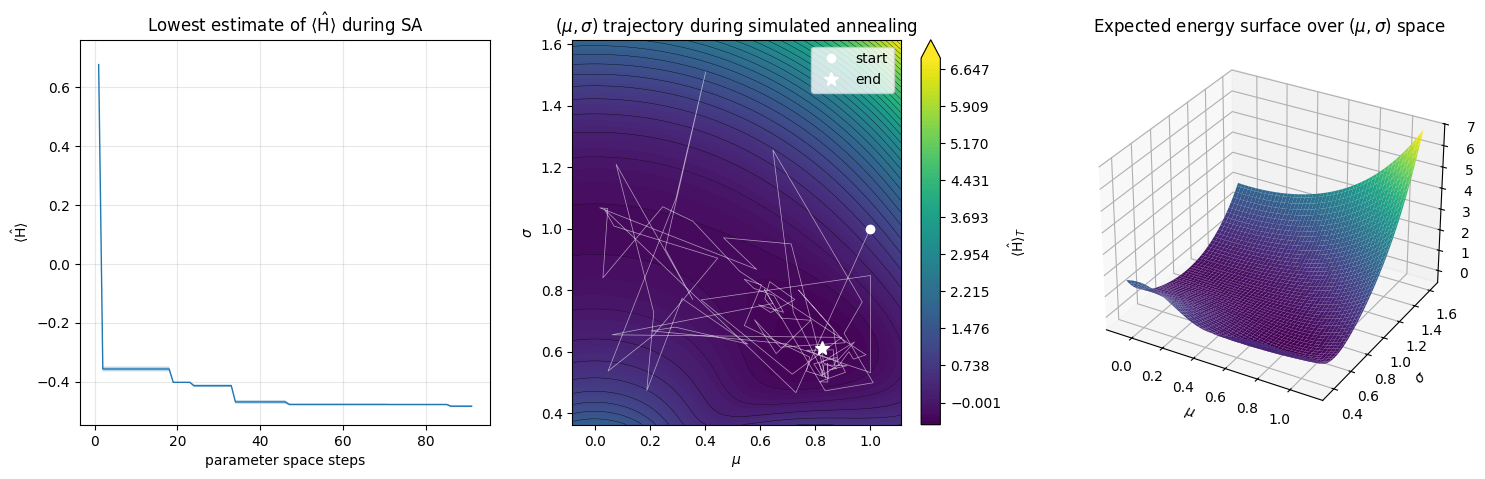

In [98]:
def read_annealing_results(filename):
    df = pd.read_csv(filename, sep=',', header=0)
    data = df.to_numpy()

    T = data[:, 0]
    mu = data[:, 1]
    sigma = data[:, 2]
    E = data[:, 3]
    E_err = data[:, 4]
    for i in range(1, E.size):
        if (E[i] >= E[i-1]):
            E[i] = E[i-1]
            E_err[i] = E_err[i-1]

    return T, mu, sigma, E, E_err

def plt_energy_expectation_history(ax, E, E_err, title):
    n = np.arange(1, E.size + 1)
    ax.plot(n, E, lw=1)
    ax.fill_between(n, E - E_err, E + E_err, alpha=0.3)
    ax.set_xlabel("parameter space steps")
    ax.set_ylabel(rf"$\langle \hat{{\mathrm{{H}}}} \rangle$")
    ax.set_title(title)
    ax.grid(alpha=0.3)

def energy_grid(mu_vals, sigma_vals):
    x = np.linspace(-10, 10, 2001)
    V = x**4 - 2.5 * x**2

    def energy(m, s):
        gm = np.exp(-(x - m)**2 / (2 * s**2))
        gp = np.exp(-(x + m)**2 / (2 * s**2))
        psi = gm + gp
        d2psi = (gm * ((x - m)**2 / s**4 - 1 / s**2)
               + gp * ((x + m)**2 / s**4 - 1 / s**2))
        num = np.trapezoid(psi * (-0.5 * d2psi + V * psi), x)
        den = np.trapezoid(psi**2, x)
        return num / den

    mu_grid, sigma_grid = np.meshgrid(mu_vals, sigma_vals)
    E_grid = np.array([[energy(m, s) for m in mu_vals] for s in sigma_vals])
    return mu_grid, sigma_grid, E_grid

def plt_energy_landscape(ax2d, ax3d, mu, sigma, title3d, title2d, n_grid=100):
    # plotting window around the trajectory, with 10% margins
    dmu = mu.max() - mu.min()
    dsig = sigma.max() - sigma.min()
    mu_min, mu_max = mu.min() - 0.1 * dmu, mu.max() + 0.1 * dmu
    sigma_min = max(sigma.min() - 0.1 * dsig, 0.05)  # keep sigma > 0
    sigma_max = sigma.max() + 0.1 * dsig

    mu_grid, sigma_grid, E_grid = energy_grid(np.linspace(mu_min, mu_max, n_grid),
                                              np.linspace(sigma_min, sigma_max, n_grid))

    # --- 3D surface ---
    ax3d.plot_surface(mu_grid, sigma_grid, E_grid, cmap="viridis")
    ax3d.set_title(title3d)
    ax3d.set_xlabel(r"$\mu$")
    ax3d.set_ylabel(r"$\sigma$")
    ax3d.set_zlabel(r"$\langle \hat{\mathrm{H}} \rangle_T$")

    # --- 2D contour map with the SA trajectory on top ---
    levels = np.linspace(E_grid.min(), E_grid.max(), 100)
    cs = ax2d.contourf(mu_grid, sigma_grid, E_grid, levels=levels,
                       cmap="viridis", extend="max")
    ax2d.contour(mu_grid, sigma_grid, E_grid, levels=levels[::3],
                 colors="k", linewidths=0.25)
    ax2d.figure.colorbar(cs, ax=ax2d, label=r"$\langle \hat{\mathrm{H}} \rangle_T$")

    ax2d.plot(mu, sigma, color="white", lw=0.5, alpha=0.6)
    ax2d.plot(mu[0], sigma[0], 'wo', label="start")
    ax2d.plot(mu[-1], sigma[-1], 'w*', ms=10, label="end")
    ax2d.set_xlabel(r"$\mu$")
    ax2d.set_ylabel(r"$\sigma$")
    ax2d.set_title(title2d)
    ax2d.legend()

    i = E_grid.argmin()
    print(f"Expected energy minimum: E = {E_grid.flat[i]:.4f} at "
          f"mu = {mu_grid.flat[i]:.3f}, sigma = {sigma_grid.flat[i]:.3f}")

T, mu, sigma, E_min, E_err = read_annealing_results("sim_results/ex8_data/simulated_annealing_history.csv")

fig = plt.figure(figsize=(18, 5))

ax3 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2)
ax1 = fig.add_subplot(1, 3, 3, projection="3d")

plt_energy_landscape(ax2, ax1, mu, sigma,
                     r"Expected energy surface over $(\mu, \sigma)$ space",
                     r"$(\mu, \sigma)$ trajectory during simulated annealing")
plt_energy_expectation_history(ax3, E_min, E_err, rf"Lowest estimate of $\langle \hat{{\mathrm{{H}}}} \rangle$ during SA")

Having found our estimate for the optimum, we can look at it in greater detail: first we extract its parameters

In [108]:
def read_best_parameters(filename):
    df = pd.read_csv(filename, sep=',', header=0)
    data = df.to_numpy()

    T = data[:, 0]
    mu = data[:, 1]
    sigma = data[:, 2]
    E = data[:, 3]
    E_err = data[:, 4]

    return mu[E.argmin()], sigma[E.argmin()]

mu_best, sigma_best = read_best_parameters("sim_results/ex8_data/simulated_annealing_history.csv")
Nblk = 100
Nsmp = 5000

blk_avgs_best = energy_block_averages(mu_best, sigma_best, Nblk, Nsmp)
progr_avg_best, progr_err_best = progressive_data(blk_avgs_best)
E_best = progr_avg_best[-1]
E_err_best = progr_err_best[-1]

and use them to sample directly its proability distribution

In [109]:
def sample_wavefunction(mu, sigma, N):
    output = subprocess.run(["./run", str(N), "ex8_sample_wavefunction", str(mu), str(sigma)], 
                            cwd="./rannyu_rng",
                            capture_output=True,
                            text=True,
                            check=True)
    return np.array([ list(map(float, line.split(','))) for line in output.stdout.strip().split('\n') ])

Nsamples = int(1e5)
samples = sample_wavefunction(mu_best, sigma_best, Nsamples)

Secondly, we can solve numerically the Schrödinger equation on a lattice:

In [104]:
def Vpot(x):
    return x**4 - 5 * x**2 / 2

def schrödinger_lattice_gs(x):
    hbar = 1
    m = 1
    N = x.size # number of lattice points
    dx = x[1] - x[0]
    V = Vpot(x)

    CDiff = np.diag(np.ones(N-1),-1)-2*np.diag(np.ones(N),0)+np.diag(np.ones(N-1),1)
    H = (-(hbar**2)*CDiff)/(2*m*dx**2) + np.diag(V)

    E,psi = np.linalg.eigh(H)
    psi = np.transpose(psi)
    psi = psi/np.sqrt(dx)
    return psi[0]**2, E[0]

xmin = samples.min()
xmax = samples.max()
dx = xmax - xmin
xmin = xmin - dx * 0.1
xmax = xmax + dx * 0.1

N_lattice_pts = int(5e3)
x_lattice = np.linspace(xmin, xmax, N_lattice_pts)
p_schrödinger, E_lattice = schrödinger_lattice_gs(x_lattice)

And compute the analytical result for the known wavefunction:

In [110]:
def analytical_distrib(x_lattice, mu, sigma):
    def p(x):
        ep = np.exp(-(x + mu)**2 / (2 * sigma**2))
        em = np.exp(-(x - mu)**2 / (2 * sigma**2))
        Z = 2 * sigma * np.sqrt(np.pi) * (1 + np.exp(-mu**2 / sigma**2))
        return (ep + em)**2 / Z
    return p(x_lattice)

p_analytical = analytical_distrib(x_lattice, mu_best, sigma_best)

Lastly we plot them all, comparing them on the same graph:

SA lowest energy expectation found: -0.4769 ± 0.0010
Lattice computation lowest eigenstate: -0.4605


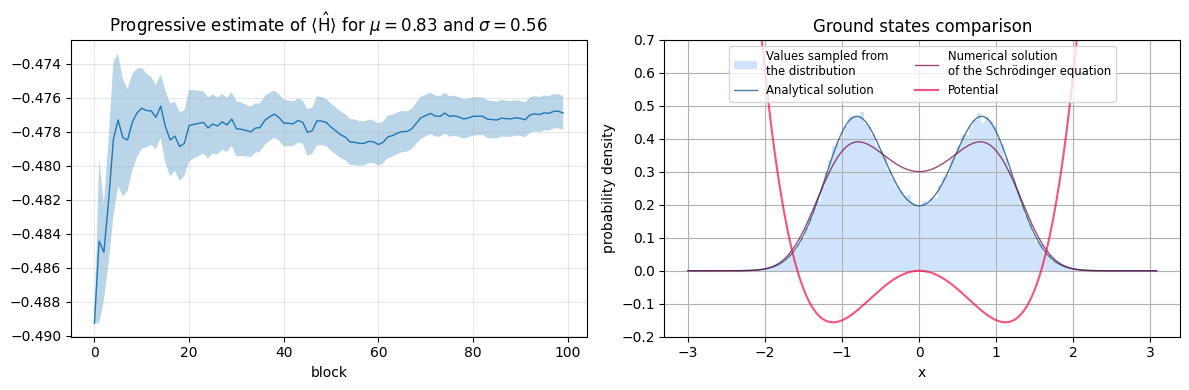

In [145]:
def plt_comparison(ax, samples, x_lattice, schrödinger_sol, analytical_sol, title):
    ax.hist(samples, bins=100, density=True, alpha=0.6, label="Values sampled from \nthe distribution", color="xkcd:powder blue")
    ax.plot(x_lattice, analytical_sol, label="Analytical solution", color='xkcd:prussian blue', lw=1.0, alpha=0.7)
    ax.plot(x_lattice, schrödinger_sol, label="Numerical solution \nof the Schrödinger equation", color='xkcd:merlot', lw=1.0, alpha=0.7)

    V_scale = 0.1
    ax.plot(x_lattice, Vpot(x_lattice) * V_scale, label="Potential", color='xkcd:pinkish red', alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.set_ylabel("probability density")
    ax.set_ylim(-0.2, 0.7)
    ax.legend(loc="upper center", ncol=2, fontsize="small")
    ax.grid(True)

fig, axs = plt.subplots(1, 2, figsize=(12,4))
plt_progr_avg(axs[0], progr_avg_best, progr_err_best, rf"Progressive estimate of $\langle \hat{{\mathrm{{H}}}} \rangle$ for $\mu = {mu_best:.2f}$ and $\sigma = {sigma_best:.2f}$")
plt_comparison(axs[1], samples, x_lattice, p_schrödinger, p_analytical, "Ground states comparison")
fig.tight_layout()
pm = '\u00B1'
print(rf"SA lowest energy expectation found: {E_best:.4f} {pm} {E_err_best:.4f}")
print(f"Lattice computation lowest eigenstate: {E_lattice:.4f}")

As we can see the distribution we obtained is not the true ground state, but it tries to get close within the family of (simpler) wavefunctions spanned by varying $\mu$ and $\sigma$.